<a href="https://colab.research.google.com/github/naziasalmani/customer-churn-prediction/blob/main/Customer_Churn_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Customer Churn Prediction Using Machine Learning

1. Project Overview

Problem Statement

Customer churn refers to the situation where customers discontinue using a company's products or services. Customer churn can negatively affect business revenue and growth.

Objective

The objective of this project is to develop a machine learning classification model that identifies customers who are likely to leave a telecommunications service provider.

Project Goals

- Analyse customer data to identify churn patterns.
- Perform data cleaning and exploratory data analysis.
- Train and compare multiple machine learning classification algorithms.
- Prioritise recall to identify as many potential churners as possible.
- Interpret model predictions using feature importance and SHAP.
- Suggest business strategies to help reduce customer churn.

Dataset

IBM Telco Customer Churn Dataset.

Machine Learning Type

Supervised Learning – Binary Classification.

Target Variable

"Churn"

- 0 = Customer stayed
- 1 = Customer churned

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Customer Churn Prediction")

Customer Churn Prediction


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn (2).csv


In [ ]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.shape

(7043, 21)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
(df['TotalCharges'].str.strip() == '').sum()

np.int64(11)

In [ ]:
df[df['TotalCharges'].str.strip() == '']

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [ ]:
df[df['TotalCharges'].str.strip() == ''][['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


In [ ]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'],errors= 'coerce')

In [ ]:
df['TotalCharges'].isnull().sum()

np.int64(11)

In [ ]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [ ]:
df['TotalCharges'].isnull().sum()

np.int64(0)

In [ ]:
df['TotalCharges'].dtype

dtype('float64')

In [ ]:
df.shape

(7043, 21)

In [ ]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [ ]:
df['Churn'].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


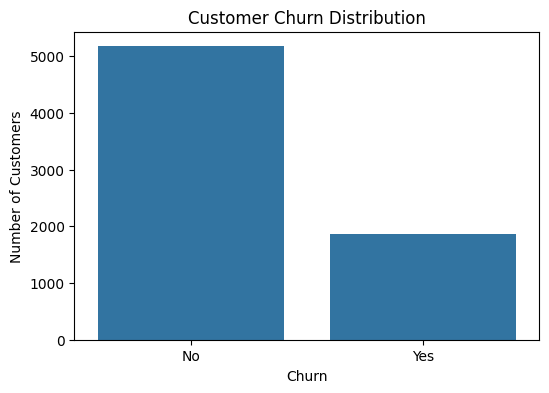

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')

plt.show()

In [ ]:
pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


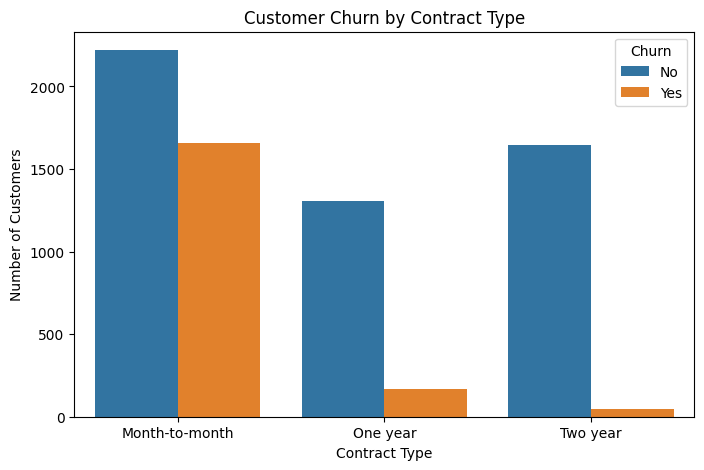

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(
data=df,
x="Contract",
hue="Churn")
plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')

plt.show()

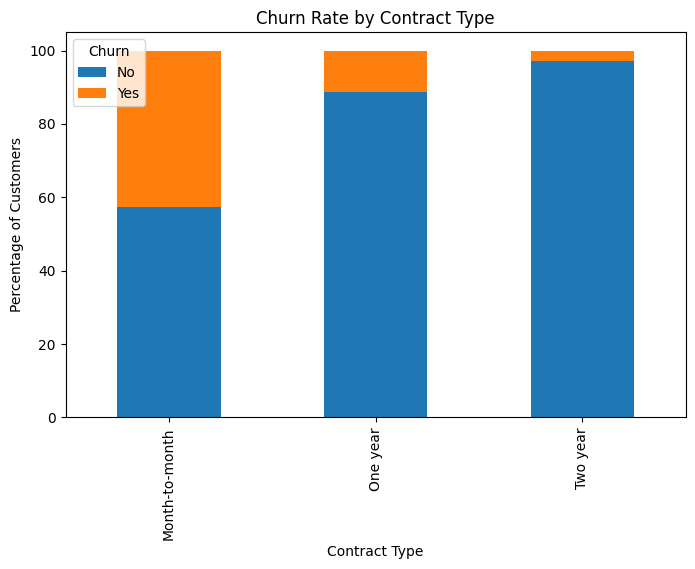

In [ ]:
churn_analysis = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

churn_analysis.plot(
    kind='bar',
    stacked=True,
    figsize=(8,5)
)

plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Percentage of Customers')
plt.legend(title='Churn')

plt.show()

Observation

Month-to-month customers have the highest churn rate.
Two-year customers have the lowest churn rate.
Longer contracts are associated with better customer retention.

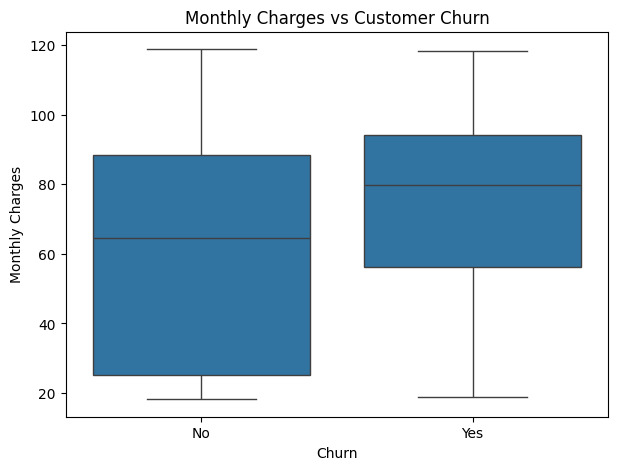

In [ ]:
plt.figure(figsize=(7,5))

sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges'
)

plt.title('Monthly Charges vs Customer Churn')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')

plt.show()

In [ ]:
df.groupby('Churn')['MonthlyCharges'].median()

,MonthlyCharges
Churn,
No,64.425
Yes,79.650


Observation

Customers who churned had higher median monthly charges.
Customers who stayed had lower median monthly charges.
Monthly charges might be associated with customer churn.

In [ ]:
df.groupby('Churn')['tenure'].mean()

,tenure
Churn,
No,37.569965
Yes,17.979133


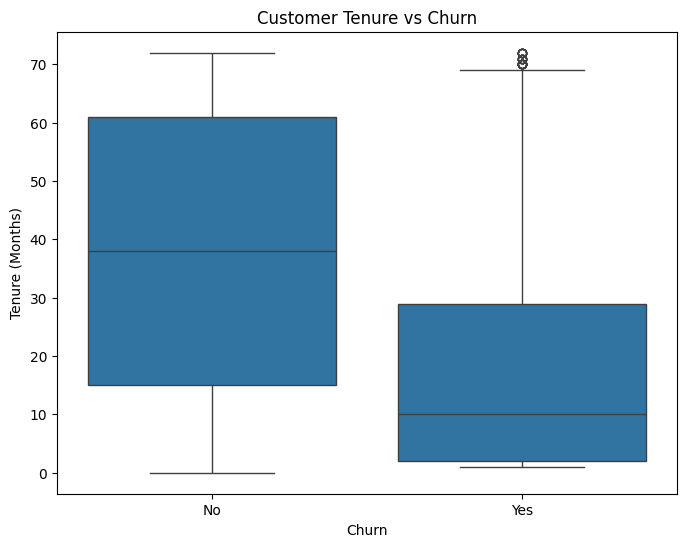

In [ ]:
plt.figure(figsize=(8,6))
sns.boxplot(
data=df,
x='Churn',
y='tenure'
)
plt.title('Customer Tenure vs Churn')
plt.xlabel('Churn')
plt.ylabel('Tenure (Months)')

plt.show()

In [ ]:
df.groupby('Churn')['tenure'].median()

,tenure
Churn,
No,38.0
Yes,10.0


Observation

Customers with longer tenure shows lower churn, suggesting that customer loyalty and retention are associated with tenure."

In [ ]:
pd.crosstab(
df['gender'],
df['Churn'],
normalize='index'
)*100

Churn,No,Yes
gender,,
Female,73.079128,26.920872
Male,73.839662,26.160338


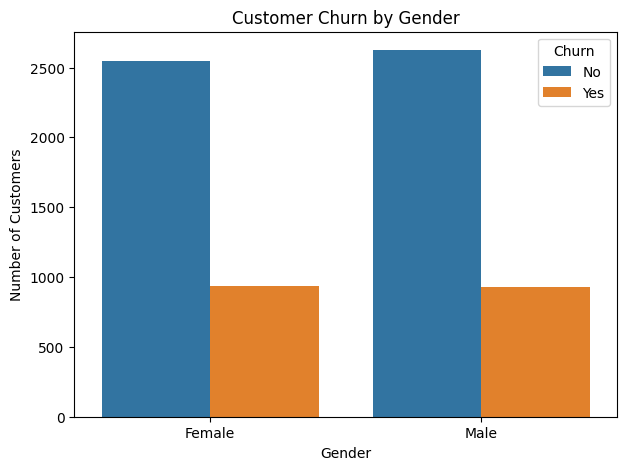

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x='gender',
    hue='Churn'
)

plt.title('Customer Churn by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

plt.show()

Observation

Male and female customers have fairly similar churn counts.
There isn't a substantial difference between their churn behaviour.
Gender may not be a particularly strong predictor of churn on its own.

In [ ]:
pd.crosstab(
    df['SeniorCitizen'],
    df['Churn'],
    normalize='index'
) * 100

Churn,No,Yes
SeniorCitizen,,
0,76.393832,23.606168
1,58.318739,41.681261


Observation

Senior citizens have a considerably higher churn rate

In [ ]:
pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize='index'
) * 100

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


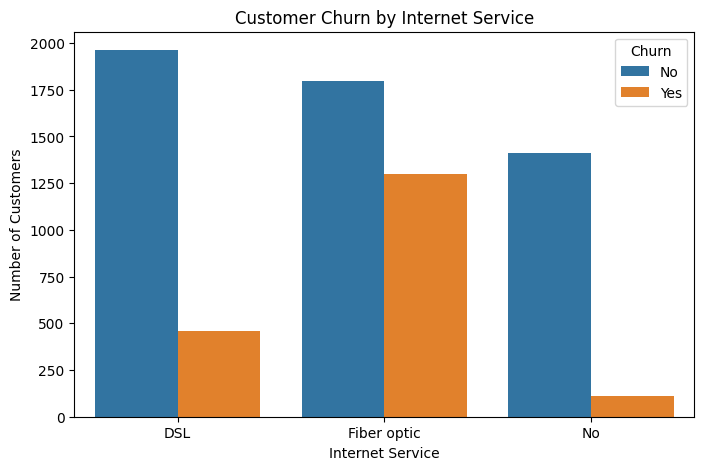

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='InternetService',
    hue='Churn'
)

plt.title('Customer Churn by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Number of Customers')

plt.show()

Fiber optic: Higher customer churn.
DSL: Comparatively lower churn.
No internet service: Also comparatively lower churn.

In [ ]:
df.groupby('InternetService')['MonthlyCharges'].mean()

,MonthlyCharges
InternetService,
DSL,58.102169
Fiber optic,91.500129
No,21.079194


In [ ]:
pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize='index'
) * 100

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


In [ ]:
df.groupby(
    ['InternetService', 'Churn']
)['MonthlyCharges'].mean()

InternetService  Churn
DSL              No       60.212105
                 Yes      49.083224
Fiber optic      No       93.932379
                 Yes      88.126484
No               No       21.136058
                 Yes      20.368142
Name: MonthlyCharges, dtype: float64

In [ ]:
pd.crosstab(
    df['OnlineSecurity'],
    df['Churn'],
    normalize='index'
) * 100

Churn,No,Yes
OnlineSecurity,,
No,58.233276,41.766724
No internet service,92.595020,7.404980
Yes,85.388806,14.611194


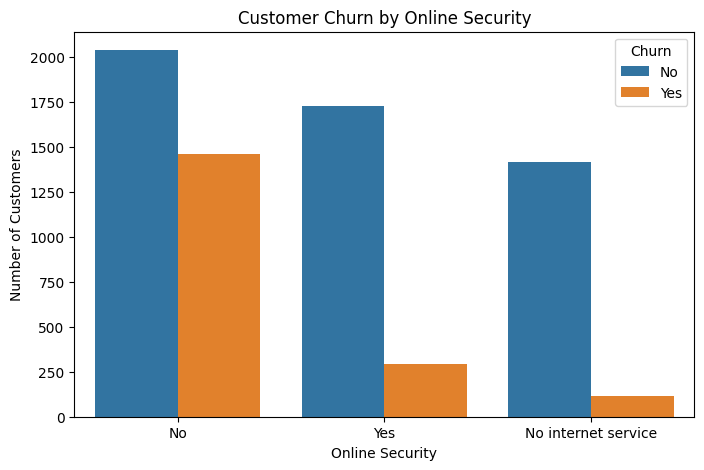

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='OnlineSecurity',
    hue='Churn'
)

plt.title('Customer Churn by Online Security')
plt.xlabel('Online Security')
plt.ylabel('Number of Customers')

plt.show()

Observation

No online security: Highest churn rate (41.77%).
No internet service: Lowest churn rate (7.40%).
Online security available: Lower churn rate (14.61%).
This suggests that customers without online security are more likely to churn.

In [ ]:
pd.crosstab(
df['TechSupport'],
df['Churn'],
normalize='index')*100

Churn,No,Yes
TechSupport,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


Observation

Customers without technical support are more likely to leave the company.

In [ ]:
pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
) * 100

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


Observation

Electronic check customers have approximately 45.29% churn, considerably higher than the other payment categories.

In [ ]:
pd.crosstab(
    df['PaymentMethod'],
    df['Contract'],
    normalize='index'
) * 100

Contract,Month-to-month,One year,Two year
PaymentMethod,,,
Bank transfer (automatic),38.147668,25.323834,36.528497
Credit card (automatic),35.676741,26.149803,38.173456
Electronic check,78.224101,14.672304,7.103594
Mailed check,55.397022,20.905707,23.697270


Observation

78.22% have month-to-month contracts.
Only 14.67% have one-year contracts.
Just 7.10% have two-year contracts.
This suggests that contract type and payment method may be related.

In [ ]:
pd.crosstab(
    [df['PaymentMethod'], df['Contract']],
    df['Churn'],
    normalize='index'
) * 100

Churn                                            No        Yes
PaymentMethod             Contract                            
Bank transfer (automatic) Month-to-month  65.874363  34.125637
                          One year        90.281330   9.718670
                          Two year        96.631206   3.368794
Credit card (automatic)   Month-to-month  67.219153  32.780847
                          One year        89.698492  10.301508
                          Two year        97.762478   2.237522
Electronic check          Month-to-month  46.270270  53.729730
                          One year        81.556196  18.443804
                          Two year        92.261905   7.738095
Mailed check              Month-to-month  68.421053  31.578947
                          One year        93.175074   6.824926
                          Two year        99.214660   0.785340

Observation

Customers using electronic checks with month-to-month contracts are more likely to discontinue their subscriptions.

In [ ]:
df = df.drop('customerID', axis=1)

In [ ]:
X = df.drop('Churn', axis= 1)
y = df['Churn']

In [ ]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 19)
Target shape: (7043,)


In [ ]:
y = y.map({
'No':0,
'Yes':1})

In [ ]:
y.value_counts()

,count
Churn,
0,5174
1,1869


## Initial Model Experiments

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 19)
X_test: (1409, 19)
y_train: (5634,)
y_test: (1409,)


In [ ]:
categorical_cols = X.select_dtypes(include=['object']).columns

numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns

print("Categorical columns:")
print(list(categorical_cols))

print("\nNumerical columns:")
print(list(numerical_cols))

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
preprocessor = ColumnTransformer(
transformers = [('num', StandardScaler(), numerical_cols),
('cat', OneHotEncoder(handle_unknown = 'ignore'), categorical_cols)])

In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [ ]:
print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Training data shape: (5634, 45)
Testing data shape: (1409, 45)


In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_processed, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
y_pred = model.predict(X_test_processed)

print(y_pred[:10])

[0 1 0 0 0 1 0 0 0 0]


In [ ]:
comparison= pd.DataFrame(
{'Actual': y_test.values[:10],
'Predicted': y_pred[:10]})
print(comparison)

   Actual  Predicted
0       0          0
1       0          1
2       0          0
3       0          0
4       0          0
5       0          1
6       0          0
7       0          0
8       0          0
9       1          0


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
print("Accuracy:",accuracy_score(y_test,y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.8055358410220014
Precision: 0.6572327044025157
Recall: 0.5588235294117647
F1 Score: 0.6040462427745664


In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test,y_pred)
print(cm)

[[926 109]
 [165 209]]


In [ ]:
model_weighted = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

model_weighted.fit(X_train_processed, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [ ]:
y_pred_weighted = model_weighted.predict(X_test_processed)

In [ ]:
print("Weighted Model Results")
print("Accuracy:", accuracy_score(y_test, y_pred_weighted))
print("Precision:", precision_score(y_test, y_pred_weighted))
print("Recall:", recall_score(y_test, y_pred_weighted))
print("F1 Score:", f1_score(y_test, y_pred_weighted))

Weighted Model Results
Accuracy: 0.7381121362668559
Precision: 0.504302925989673
Recall: 0.7834224598930482
F1 Score: 0.6136125654450262


In [ ]:
cm_weighted = confusion_matrix(y_test, y_pred_weighted)

print(cm_weighted)

[[747 288]
 [ 81 293]]


In [ ]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(n_estimators = 100, random_state= 42, n_jobs=-1)
rf_model.fit(X_train_processed, y_train)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [ ]:
y_pred_rf = rf_model.predict(X_test_processed)

In [ ]:
print("Random Forest Results")

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))

Random Forest Results
Accuracy: 0.7863733144073811
Precision: 0.6254295532646048
Recall: 0.48663101604278075
F1 Score: 0.5473684210526316


In [ ]:
cm_rf = confusion_matrix(y_test,y_pred_rf)
print(cm_rf)

[[926 109]
 [192 182]]


In [ ]:
rf_balanced = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_balanced.fit(X_train_processed, y_train)

RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=42)

In [ ]:
y_pred_rf_balanced = rf_balanced.predict(X_test_processed)

In [ ]:
print("Balanced Random Forest Results")

print("Accuracy:", accuracy_score(y_test, y_pred_rf_balanced))
print("Precision:", precision_score(y_test, y_pred_rf_balanced))
print("Recall:", recall_score(y_test, y_pred_rf_balanced))
print("F1 Score:", f1_score(y_test, y_pred_rf_balanced))

print(confusion_matrix(y_test, y_pred_rf_balanced))

Balanced Random Forest Results
Accuracy: 0.7806955287437899
Precision: 0.6101694915254238
Recall: 0.48128342245989303
F1 Score: 0.5381165919282511
[[920 115]
 [194 180]]


In [ ]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel='rbf',
    random_state=42
)

svm_model.fit(X_train_processed, y_train)

SVC(random_state=42)

In [ ]:
y_pred_svm = svm_model.predict(X_test_processed)

In [ ]:
print("SVM Results")

print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm))
print("Recall:", recall_score(y_test, y_pred_svm))
print("F1 Score:", f1_score(y_test, y_pred_svm))

print(confusion_matrix(y_test, y_pred_svm))

SVM Results
Accuracy: 0.7913413768630234
Precision: 0.6418439716312057
Recall: 0.4839572192513369
F1 Score: 0.551829268292683
[[920 115]
 [194 180]]


In [ ]:
svm_balanced = SVC(
    kernel='rbf',
    class_weight='balanced',
    random_state=42
)

svm_balanced.fit(X_train_processed, y_train)

SVC(class_weight='balanced', random_state=42)

In [ ]:
y_pred_svm_balanced = svm_balanced.predict(X_test_processed)

In [ ]:
print("Balanced SVM Results")

print("Accuracy:", accuracy_score(y_test, y_pred_svm_balanced))
print("Precision:", precision_score(y_test, y_pred_svm_balanced))
print("Recall:", recall_score(y_test, y_pred_svm_balanced))
print("F1 Score:", f1_score(y_test, y_pred_svm_balanced))

print(confusion_matrix(y_test, y_pred_svm_balanced))

Balanced SVM Results
Accuracy: 0.7437899219304471
Precision: 0.511504424778761
Recall: 0.7727272727272727
F1 Score: 0.6155484558040468
[[759 276]
 [ 85 289]]


In [ ]:
!pip install xgboost
from xgboost import XGBClassifier

In [ ]:
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
    eval_metric='logloss'
)
xgb_model.fit(X_train_processed, y_train)
y_pred_xgb = xgb_model.predict(X_test_processed)

In [ ]:
print("XGBoost Results")

print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall:", recall_score(y_test, y_pred_xgb))
print("F1 Score:", f1_score(y_test, y_pred_xgb))

print(confusion_matrix(y_test, y_pred_xgb))

XGBoost Results
Accuracy: 0.8034066713981547
Precision: 0.6632996632996633
Recall: 0.5267379679144385
F1 Score: 0.587183308494784
[[935 100]
 [177 197]]


In [ ]:
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_weight = negative / positive

print(scale_weight)

2.768561872909699


In [ ]:
xgb_balanced = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    scale_pos_weight=scale_weight,
    random_state=42,
    eval_metric='logloss'
)

xgb_balanced.fit(X_train_processed, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:
y_pred_xgb_balanced = xgb_balanced.predict(X_test_processed)

In [ ]:
print("Balanced XGBoost Results")

print("Accuracy:", accuracy_score(y_test, y_pred_xgb_balanced))
print("Precision:", precision_score(y_test, y_pred_xgb_balanced))
print("Recall:", recall_score(y_test, y_pred_xgb_balanced))
print("F1 Score:", f1_score(y_test, y_pred_xgb_balanced))

print(confusion_matrix(y_test, y_pred_xgb_balanced))

Balanced XGBoost Results
Accuracy: 0.7466288147622427
Precision: 0.5147313691507799
Recall: 0.7941176470588235
F1 Score: 0.6246056782334385
[[755 280]
 [ 77 297]]


In [ ]:
y_prob_xgb = xgb_balanced.predict_proba(X_test_processed)[:, 1]
print(y_prob_xgb[:10])

[0.04081839 0.9005183  0.14816332 0.601362   0.02138323 0.80686706
 0.7073944  0.31552777 0.02064675 0.6023074 ]


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.3, 0.4, 0.5]

for threshold in thresholds:

    y_pred_threshold = (y_prob_xgb >= threshold).astype(int)

    print("Threshold:", threshold)
    print("Precision:", precision_score(y_test, y_pred_threshold))
    print("Recall:", recall_score(y_test, y_pred_threshold))
    print("F1 Score:", f1_score(y_test, y_pred_threshold))
    print("--------------------------------")

Threshold: 0.3
Precision: 0.4336283185840708
Recall: 0.9171122994652406
F1 Score: 0.5888412017167381
--------------------------------
Threshold: 0.4
Precision: 0.4751131221719457
Recall: 0.8422459893048129
F1 Score: 0.6075216972034716
--------------------------------
Threshold: 0.5
Precision: 0.5147313691507799
Recall: 0.7941176470588235
F1 Score: 0.6246056782334385
--------------------------------


## Final Validation and Test Evaluation

In [ ]:
from sklearn.model_selection import train_test_split

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training shape:", X_train_new.shape)
print("Validation shape:", X_val.shape)

Training shape: (4507, 19)
Validation shape: (1127, 19)


In [ ]:
X_train_processed_new = preprocessor.fit_transform(X_train_new)

X_val_processed = preprocessor.transform(X_val)

print("Training:", X_train_processed_new.shape)
print("Validation:", X_val_processed.shape)

Training: (4507, 45)
Validation: (1127, 45)


In [ ]:
negative = (y_train_new == 0).sum()
positive = (y_train_new == 1).sum()

scale_weight = negative / positive

print("Scale weight:", scale_weight)

Scale weight: 2.7683946488294313


In [ ]:
xgb_balanced = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    scale_pos_weight=scale_weight,
    random_state=42,
    eval_metric='logloss'
)

xgb_balanced.fit(X_train_processed_new, y_train_new)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:
y_val_prob = xgb_balanced.predict_proba(X_val_processed)[:, 1]

print(y_val_prob[:10])

[0.46654987 0.05392556 0.07027332 0.11055719 0.4660232  0.12846026
 0.34157044 0.06033988 0.0381804  0.4337776 ]


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.3, 0.4, 0.5, 0.6]

for threshold in thresholds:
    y_val_pred = (y_val_prob >= threshold).astype(int)

    print("Threshold:", threshold)
    print("Precision:", precision_score(y_val, y_val_pred))
    print("Recall:", recall_score(y_val, y_val_pred))
    print("F1 Score:", f1_score(y_val, y_val_pred))
    print("--------------------------")

Threshold: 0.3
Precision: 0.4359805510534846
Recall: 0.8996655518394648
F1 Score: 0.5873362445414847
--------------------------
Threshold: 0.4
Precision: 0.4772727272727273
Recall: 0.842809364548495
F1 Score: 0.6094316807738815
--------------------------
Threshold: 0.5
Precision: 0.5152173913043478
Recall: 0.7926421404682275
F1 Score: 0.6245059288537549
--------------------------
Threshold: 0.6
Precision: 0.5944444444444444
Recall: 0.7157190635451505
F1 Score: 0.6494688922610015
--------------------------


In [ ]:
thresholds = [0.20, 0.25, 0.28, 0.29]

for threshold in thresholds:
    y_val_pred = (y_val_prob >= threshold).astype(int)

    print("Threshold:", threshold)
    print("Precision:", precision_score(y_val, y_val_pred))
    print("Recall:", recall_score(y_val, y_val_pred))
    print("F1 Score:", f1_score(y_val, y_val_pred))
    print("--------------------------")

Threshold: 0.2
Precision: 0.38639455782312926
Recall: 0.9498327759197325
F1 Score: 0.5493230174081238
--------------------------
Threshold: 0.25
Precision: 0.4159159159159159
Recall: 0.9264214046822743
F1 Score: 0.5740932642487047
--------------------------
Threshold: 0.28
Precision: 0.4265402843601896
Recall: 0.903010033444816
F1 Score: 0.5793991416309013
--------------------------
Threshold: 0.29
Precision: 0.42971246006389774
Recall: 0.8996655518394648
F1 Score: 0.5816216216216217
--------------------------


## Final Model Evaluation

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

final_threshold = 0.28

y_test_prob = xgb_balanced.predict_proba(X_test_processed)[:, 1]

y_test_pred = (y_test_prob >= final_threshold).astype(int)

print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1 Score:", f1_score(y_test, y_test_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

Accuracy: 0.6444286728176012
Precision: 0.4218942189421894
Recall: 0.9171122994652406
F1 Score: 0.577927548441449

Confusion Matrix:
[[565 470]
 [ 31 343]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.55      0.69      1035
           1       0.42      0.92      0.58       374

    accuracy                           0.64      1409
   macro avg       0.68      0.73      0.64      1409
weighted avg       0.81      0.64      0.66      1409



## Feature Importance Analysis

In [ ]:
import pandas as pd

feature_names = preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': xgb_balanced.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance.head(15))

                                Feature  Importance
36         cat__Contract_Month-to-month    0.503300
16     cat__InternetService_Fiber optic    0.091716
27                  cat__TechSupport_No    0.063519
18               cat__OnlineSecurity_No    0.052956
17              cat__InternetService_No    0.031834
35             cat__StreamingMovies_Yes    0.028574
37               cat__Contract_One year    0.027359
43  cat__PaymentMethod_Electronic check    0.022888
38               cat__Contract_Two year    0.021942
30                  cat__StreamingTV_No    0.017135
1                           num__tenure    0.016648
21                 cat__OnlineBackup_No    0.010312
6                       cat__Partner_No    0.008959
12                cat__MultipleLines_No    0.008636
8                    cat__Dependents_No    0.007720


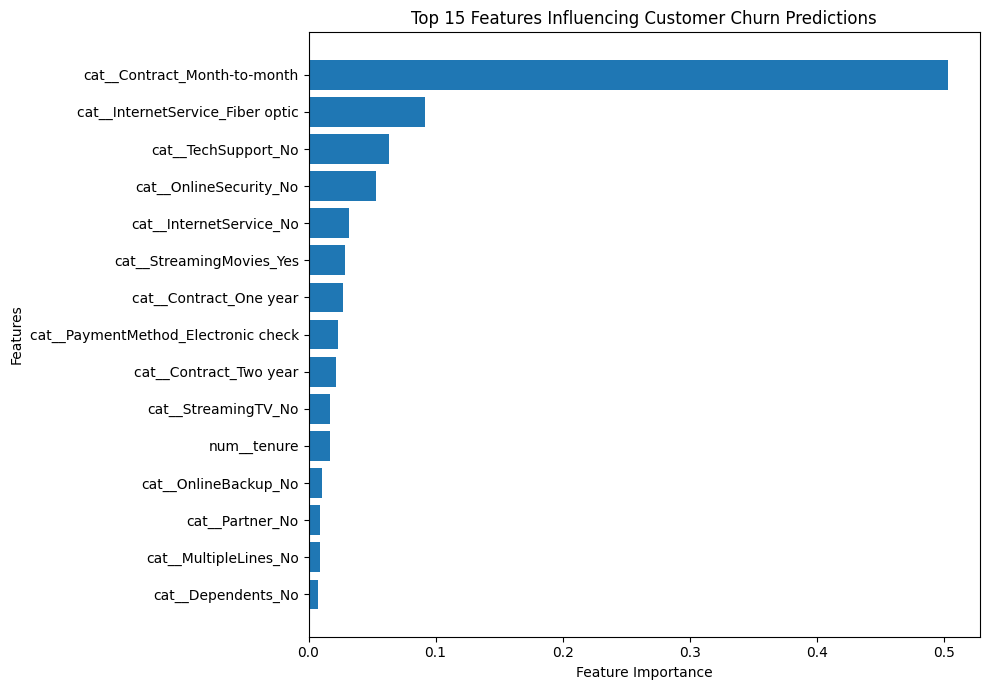

In [ ]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15).sort_values(
    by='Importance'
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Features Influencing Customer Churn Predictions")

plt.tight_layout()
plt.show()

Observation

50.33% of month-to-month customers will churn.
Month-to-month contract is an influential feature in the model's predictions.

## SHAP Explainability Analysis

In [ ]:
!pip install shap
import shap

In [ ]:
explainer = shap.TreeExplainer(xgb_balanced)

shap_values = explainer.shap_values(X_val_processed)

print("SHAP values shape:", shap_values.shape)

SHAP values shape: (1127, 45)


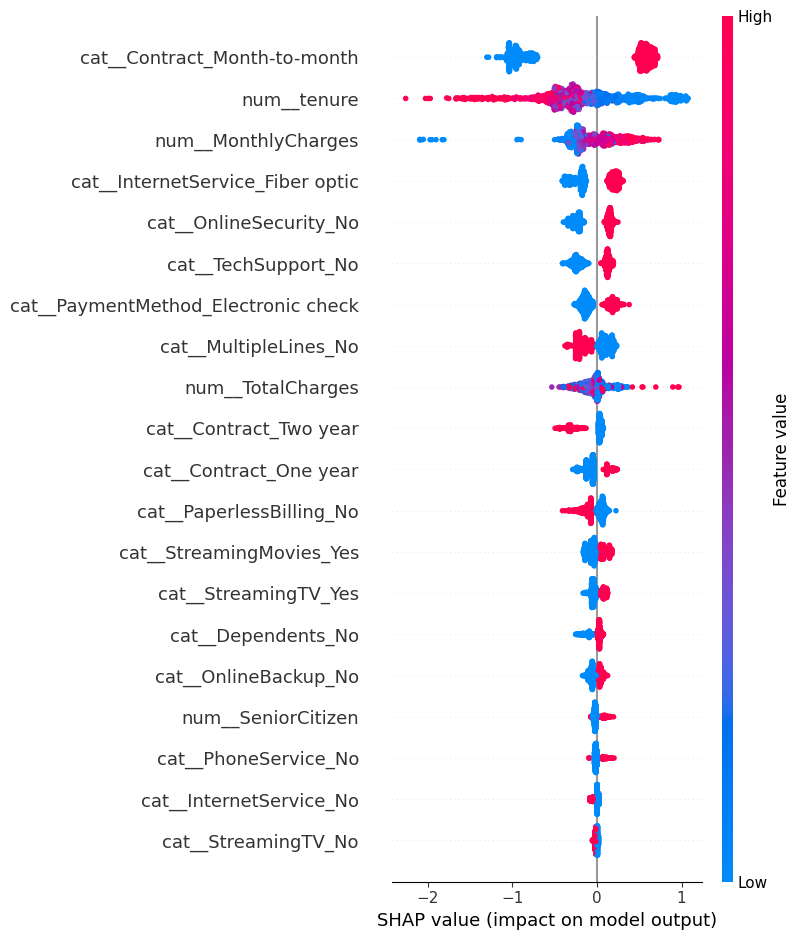

In [ ]:
shap.summary_plot(
    shap_values,
    X_val_processed,
    feature_names=feature_names
)

SHAP Interpretation

SHAP (SHapley Additive exPlanations) was used to understand how individual features influence the model's predictions.

The SHAP summary plot shows:

- Features are ranked according to their mean absolute SHAP values.
- Positive SHAP values push predictions towards customer churn.
- Negative SHAP values push predictions away from customer churn.
- Red indicates higher feature values, while blue indicates lower feature values.

The analysis highlights the importance of contract type, customer tenure, monthly charges, and internet service in the model's predictions.

## Business Insights and Recommendations

Business Insights and Recommendations
Based on Exploratory Data Analysis (EDA), model evaluation, and SHAP analysis, the following insights were identified:

Key Business Insights


Month-to-Month Contracts: Customers with month-to-month contracts show a significantly higher churn tendency compared with customers on longer-term contracts.



Customer Tenure: Customers with shorter tenure are more likely to be identified as potential churners. Early customer engagement is therefore important.



Monthly Charges: Higher monthly charges are associated with increased churn risk in the dataset.



Internet Service: Fiber optic customers show higher churn patterns compared with other internet service groups.



Additional Services: Customers without online security and technical support show higher churn patterns.



Payment Method: Customers using electronic checks have a higher observed churn rate than customers using automatic payment methods.



Business Recommendations

Offer attractive discounts or benefits to encourage month-to-month customers to choose longer contracts.
Introduce an onboarding and engagement programme for newly joined customers.
Review pricing plans and provide suitable packages to customers with higher monthly charges.
Investigate customer satisfaction among fiber optic users.
Promote online security and technical support services.
Encourage convenient automatic payment options where appropriate.

Business Objective
The model was designed to identify as many potential churners as possible. Therefore, recall was prioritised during threshold selection.

Model Limitations

1. False Positives: The model has a relatively low precision of 42.19%, meaning many customers predicted to churn may actually stay.

2. Dataset Limitations: The model was trained using the IBM Telco Customer Churn dataset. Its performance may differ on real-world company data.

3. Feature Limitations: Predictions depend on the available customer information. Other factors, such as customer satisfaction and competitor offers, may also influence churn.

4. Model Interpretability: Feature importance and SHAP explain model behaviour but do not establish causal relationships.

5. Threshold Trade-off: The selected threshold of 0.28 prioritises recall, resulting in more false positives.

Future Improvements

- Experiment with hyperparameter tuning.
- Test additional classification algorithms.
- Improve precision while maintaining high recall.
- Evaluate the model on newer and more diverse customer datasets.
- Integrate the model into a dashboard for customer-retention teams.

Conclusion

The Customer Churn Prediction project demonstrates how machine learning can be used to identify customers who are likely to discontinue a service.

The project involved data cleaning, exploratory data analysis, feature preprocessing, model training, evaluation, and model interpretation using SHAP.

Among the experiments, a class-weighted XGBoost classifier was selected. A decision threshold of 0.28 was chosen using validation data to prioritise churn detection.

On the independent test set, the model achieved 91.71% recall, identifying 343 out of 374 actual churners.

Although the model produces false positives, it provides a useful starting point for identifying at-risk customers and supporting proactive customer-retention strategies.

Overall, this project demonstrates the practical application of data science and machine learning to a real-world business problem.